<a href="https://colab.research.google.com/github/Luisen25/ELe/blob/main/Modelo_simplificado_de_tres_poros_Rippe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



Modelo simplificado de tres poros Rippe



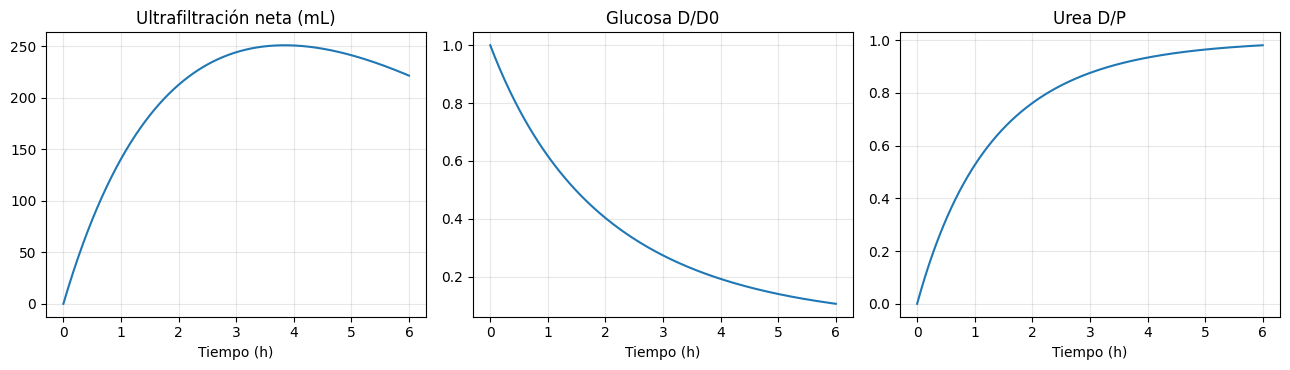

UF neta a 6 h: 222 mL | D/P urea: 0.98 | glucosa D/D0: 0.11


In [1]:
"""
Modelo simplificado de tres poros (Rippe) para una permanencia de diálisis peritoneal.
Unidades: volumen en mL, tiempo en min, concentración en mmol/L (= µmol/mL),
masa de soluto en µmol, presión en mmHg.
"""
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ---------------- Parámetros (ilustrativos; calibrar con datos) ----------------
RT = 19.3                 # mmHg por mmol/L
LpS = 0.074               # mL/min/mmHg, conductancia hidráulica total
alpha = {"aq": 0.005, "small": 0.915, "large": 0.08}   # fracción de LpS por poro

dP = 12.0                 # mmHg, presión capilar - presión intraperitoneal
dPi_onc = 20.0            # mmHg, gradiente oncótico efectivo

# Coeficientes de reflexión por poro
sig_glu = {"aq": 1.0, "small": 0.02, "large": 0.0}
sig_ure = {"aq": 1.0, "small": 0.0,  "large": 0.0}
sig_onc = {"aq": 0.0, "small": 0.9,  "large": 0.2}

PS = {"glu": 16.0, "ure": 25.0}        # mL/min, difusión en poros pequeños
Cp = {"glu": 5.5, "ure": 25.0}         # mmol/L en plasma (constante)
Jl = 0.3                               # mL/min, absorción linfática

# ---------------- Ecuaciones ----------------
def patlak(Jv, sigma, PS_, Cp_, Cd_):
    """Flujo de soluto (µmol/min), convección + difusión. Positivo: sangre -> dializado."""
    Jc = Jv * (1.0 - sigma)
    Pe = Jc / PS_
    if abs(Pe) < 1e-6:
        return PS_ * (Cp_ - Cd_)
    return Jc * (Cp_ - Cd_ * np.exp(-Pe)) / (1.0 - np.exp(-Pe))

def modelo(t, y):
    Vd, Ng, Nu = y
    Cg, Cu = Ng / Vd, Nu / Vd

    Jv = {}
    for p in alpha:
        osm = RT * (sig_glu[p] * (Cg - Cp["glu"]) + sig_ure[p] * (Cu - Cp["ure"]))
        Jv[p] = alpha[p] * LpS * (dP + osm - sig_onc[p] * dPi_onc)
    Jv_tot = sum(Jv.values())

    Js_g = patlak(Jv["small"], sig_glu["small"], PS["glu"], Cp["glu"], Cg) + Jv["large"] * Cp["glu"]
    Js_u = patlak(Jv["small"], sig_ure["small"], PS["ure"], Cp["ure"], Cu) + Jv["large"] * Cp["ure"]

    dVd = Jv_tot - Jl
    dNg = Js_g - Jl * Cg
    dNu = Js_u - Jl * Cu
    return [dVd, dNg, dNu]

# ---------------- Simulación: 6 h, 2 L de dextrosa 2.27 % (~126 mmol/L) ----------------
V0, Cg0 = 2000.0, 126.0
y0 = [V0, Cg0 * V0, 0.0]                    # [volumen, masa glucosa, masa urea]
t_eval = np.linspace(0, 360, 361)

sol = solve_ivp(modelo, (0, 360), y0, t_eval=t_eval, method="LSODA", rtol=1e-8, atol=1e-8)
Vd, Ng, Nu = sol.y
Cg, Cu = Ng / Vd, Nu / Vd

# ---------------- Gráficas ----------------
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
ax[0].plot(sol.t / 60, Vd - V0);      ax[0].set_title("Ultrafiltración neta (mL)")
ax[1].plot(sol.t / 60, Cg / Cg0);     ax[1].set_title("Glucosa D/D0")
ax[2].plot(sol.t / 60, Cu / Cp["ure"]); ax[2].set_title("Urea D/P")
for a in ax:
    a.set_xlabel("Tiempo (h)")
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"UF neta a 6 h: {Vd[-1] - V0:.0f} mL | D/P urea: {Cu[-1] / Cp['ure']:.2f} | "
      f"glucosa D/D0: {Cg[-1] / Cg0:.2f}")